# View 2: Latent Space Projections (UMAP)
Visualizes AkidaNet penultimate representation drift under corruption and where the CNN and Akida model disagree.

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap
import tensorflow as tf

In [17]:
df = pd.read_parquet("results_card/predictions_with_embeddings.parquet")
os.makedirs("../figures/phase1_human", exist_ok=True)

#df_sample = df.groupby(["corruption", "severity"]).sample(n=200, random_state=42) # subsample, 30k images is too heavy for UMAP memory limits
features = np.vstack(df["embedding"].values)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embeddings_2d = reducer.fit_transform(features)

df["umap_x"] = embeddings_2d[:, 0]
df["umap_y"] = embeddings_2d[:, 1]

/home/user/.venvs/ai-vis-2026/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Plot AkidaNet Latent Drift

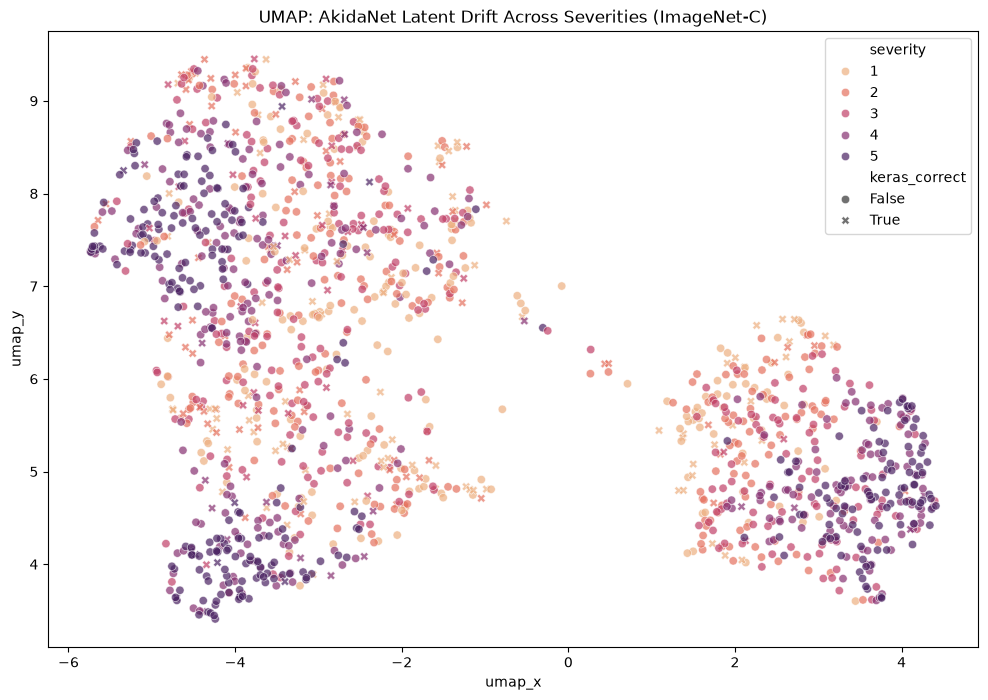

In [18]:
plt.figure(figsize=(12, 8))

sns.scatterplot(data=df, x="umap_x", y="umap_y",hue="severity", style="keras_correct", alpha=0.7, palette="flare")

plt.title("UMAP: AkidaNet Latent Drift Across Severities (ImageNet-C)")

plt.savefig("../figures/phase1_human/akidanet_umap_drift.png", bbox_inches="tight")#store image
plt.show()

**H3: Fog creates background-driven error sub-clusters (UMAP View)** <br>
Under high severity fog, the latent embeddings of misclassified images do not just form one random mass; they form distinct, dense sub-clusters grouped by shared background colors (e.g., all sky/outdoor backgrounds) rather than primary objects. 

* We reject H3 if: The UMAP error clusters do not visually correlate with shared background traits.

* To dig deeper: We will isolate the densest error clusters in the 2D projection, inspect the original input images within them, and determine exactly what visual features (like color palettes or backgrounds) distinguish these dense sub-clusters from the sparser regions of the latent space.

Found 47 misclassified images in the selected UMAP cluster.


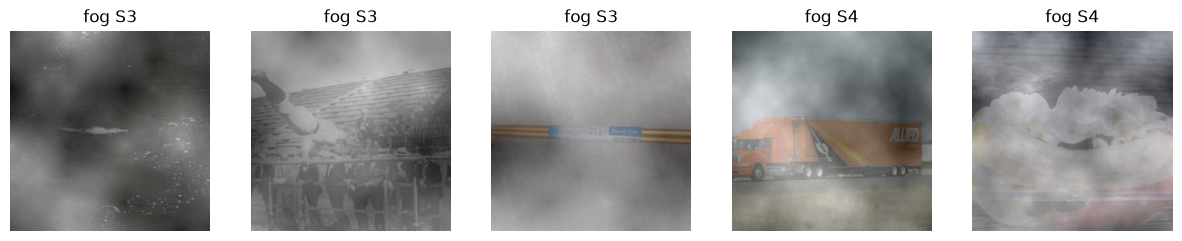

In [ ]:
X_MIN, X_MAX = -5.0, -4.0   
Y_MIN, Y_MAX = 3.5, 4.5 

# filter df to grab only the misclassified images sitting inside that coordinate box
cluster_imgs = df[(df["umap_x"] >= X_MIN) & (df["umap_x"] <= X_MAX) & (df["umap_y"] >= Y_MIN) & (df["umap_y"] <= Y_MAX) &(df["keras_correct"] == False)]

print(f"Found {len(cluster_imgs)} misclassified images in the selected UMAP cluster.")

fig, axes = plt.subplots(1, min(5, len(cluster_imgs)), figsize=(15, 3))
if len(cluster_imgs) > 0:
    if len(cluster_imgs) == 1: axes = [axes]
        
    for ax, (_, row) in zip(axes, cluster_imgs.head(5).iterrows()):
        img_path = f"../data/imagenet_subset/imagenet-c/{row['corruption']}/{row['severity']}/{row['image_id']}"
        img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"{row['corruption']} S{row['severity']}")
plt.show()

**Conclusion for Hypothesis 3**

Based on the UMAP projection and the drill-down visual inspection, we fail to reject Hypothesis 3. <br>

**Visual Evidence & Behavioral Shift:** <br>
The UMAP plot demonstrates that as corruption severity increases, the latent embeddings do not scatter randomly; instead, they collapse into distinct, highly dense sub-clusters. <br>

When we drill down into a specific high-density error cluster, the sampled images reveal a clear, systematic failure mode. As seen in the output, despite containing entirely different ground-truth objects (e.g., a truck, stadium seating, ...), all the misclassified images are heavily dominated by the exact same cloudy, gray-white fog artifact. The synthetic fog overlay washes out the fine details of the primary objects and unifies the images visually.  <br>

This confirms that under heavy corruption, AkidaNet's penultimate layer is no longer extracting features from the underlying objects. Instead, the network's latent representations are hijacked by the dominant, shared "texture" of the fog itself, forcing completely unrelated classes into the exact same region of the latent space.